# 3D coarse graining of an erodible bed

In this example, we coarse grain a 3D MFiX simulation of an erodible bed of spherical particles (no fluid) with periodic boundaries, and plot vertical profiles of the coarse-grained fields over time.

The files required for this example can be found in the repository:

- The DEM simulation data files in `examples/data_examples/erodible_bed/DEM_data/` (one time step, `t = 85`)
- Pysammos output for 145 time steps in `examples/data_examples/erodible_bed/Pysammos_data_paper/`, used for the time series plots
- The configuration file `config.ini` in `examples/erodible_bed/`

The coarse graining can also be run from the `compute_CG.ipynb` notebook in `examples/erodible_bed/`.

## Import packages

In [1]:
from pysammos.utils.config_loader import load_config
from pysammos.coarse_graining import CoarseGraining
from pysammos.data_write.h5.writer import H5XarrayManager
from pysammos.post_averaging.profiles import VerticalIntegrator

Hello from pysammos
Loading macroscopic_fields package...
Loading data_read package...
Loading particle_phase package...
Loading spatial_weights package...
Loading neighbour_search package...
Loading grid_generation package...
Loading data_handle package...
Loading data_write package...
Loading post_averaging package...


In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

In [1]:
from pathlib import Path
import os

# The paths inside config.ini (DEM data, output folder) are relative to the example folder,
# so we work from examples/erodible_bed/ and read its config.ini.
if "EXAMPLE_DIR" not in globals():          # resolve once, so the cell can be re-run
    EXAMPLE_DIR = (Path.cwd() / "../../examples/erodible_bed").resolve()
os.chdir(EXAMPLE_DIR)
CONFIG_FILE = EXAMPLE_DIR / "config.ini"
print("Working directory:", Path.cwd())

Working directory: /exports/csce/datastore/geos/users/s1857688/Coarse_Graining/pysammos/examples/erodible_bed


## The configuration file

For a description of every section, see the bedload transport example. The file used here is:

In [2]:
print(CONFIG_FILE.read_text())

[paths]
particles_path = ../data_examples/erodible_bed/DEM_data/DES_
contacts_path = ../data_examples/erodible_bed/DEM_data/FC_
output_path = ./PysammosCG/

[timesteps]
t0 = 85
tf = 85
dt = 1
t_pad = 4

[smoothing_function]
type = Lucy

[flags]
partialignore = True

[key_mapping]
Global_ID = Particle_ID
Particle_Velocity = Velocity
Particle_Diameter = Diameter
Particle_Density = Density
Particle_Volume = Volume
Particle_Mass = Mass
Particle_Radius = None
Coordination_Number = None
Particle_i_ID = Particle_ID_1
Particle_j_ID = Particle_ID_2
Force_ij = FORCE_CHAIN_FN
Contact_ij = None

[DEM_software]
name = mfix
 
[grid_info]
grid_dimension = 3
grid_axes = xyz
automatic_grid = False
x_min = 0.005
x_max = 0.10
y_min = 0.005
y_max = 0.44
z_min = 0.005
z_max = 0.05
x_transect = None
y_transect = None
z_transect = None
x_axis_periodic = True
y_axis_periodic = False
z_axis_periodic = True

[simulation_box]
# limits of the DEM simulation box; required on every periodic axis in [grid_info]
x_ra

Compared with the 2D bedload transport example:

- `grid_dimension = 3` and `grid_axes = xyz`: the fields are computed on a 3D grid, with the ranges `x_min` ... `z_max` (`automatic_grid = False`). The vertical axis is `y`.
- `x_axis_periodic = True` and `z_axis_periodic = True`: the domain is periodic in both horizontal directions.
- `Force_ij = FORCE_CHAIN_FN` and `Contact_ij = None`: the contact points are not in the MFiX output, so Pysammos calculates them from the particle positions and diameters.

## Initialise the `CoarseGraining` class

`load_config` returns the arguments of `CoarseGraining` as a dictionary, so they can be passed directly with `**`. You can also give each argument explicitly, as shown in the bedload transport example.

In [5]:
cfg = load_config(CONFIG_FILE)
CG = CoarseGraining(**cfg)

Output path created: ./PysammosCG/


<div class="alert alert-warning">

**Re-running the coarse graining:** Pysammos writes its results to `output_path`. If you have already run the workflow and want to run it again with a different number of time steps, a different spatial scale (grid/kernel width) or different exported variables, either change `output_path` to a new folder name (e.g. `./PysammosCG_run2/`) or delete the previous results first.

</div>

## Run the coarse graining

The whole workflow can be run with a single command:

```python
CG.run()
```

Here we run it step by step instead, to show what each step does.

### 1. Load the size-relevant particle data for the first time step

In [6]:
Bounds_t0, Diameter_t0, Density_t0, Mass_t0, GlobalID_t0 = CG.data_sampling()

Sampling data for the first time step to obtain particle properties and bounds ... 
XML-based PolyData detected.


### 2. Calculate the particle size statistics

In [7]:
CG.get_particle_size_statistics(Diameter_t0, Mass_t0)
print(">> Particle size statistics: ")
print("       d43: ", CG.d43)
print("       dmax: ", CG.dmax)
print("       d50: ", CG.d50)
print("       d32: ", CG.d32)
print("       drms: ", CG.drms)

>> Particle size statistics: 
       d43:  0.005285499695006148
       dmax:  0.0055
       d50:  0.0055
       d32:  0.005273755565943092
       drms:  0.005255948948344964


### 3. Get the phases

In [8]:
CG.get_particle_phases(Diameter_t0, Density_t0, GlobalID_t0, 8)
print(">> Phases: ")
print("       Diameters: ", CG.phases[:,0])
print("       Densities: ", CG.phases[:,1])

Ignoring phases. Using mean density and d50 as phase.
>> Phases: 
       Diameters:  [0.00527376]
       Densities:  [1050.]


### 4. Calculate the coarse-graining resolution

The argument is the reference diameter; a larger value gives a wider kernel (larger `w` and cutoff `c`).

In [9]:
CG.set_resolution(CG.d43)
print(">> Coarse Graining resolution: ")
print("       c:", CG.c)
print("       w:", CG.w)

>> Coarse Graining resolution: 
       c: 0.007928249542509222
       w: 0.003964124771254611


### 5. Generate the coarse-graining grid

In [10]:
CG.generate_grid()
print(">> Grid: ")
print("       Grid Points: ", CG.GridPoints.shape, "First Point: ", CG.GridPoints[0])
print("       Nodes: ", CG.Nodes)
print("       Spacing: ", CG.Spacing)

Generating Grid with Customised Grid Ranges
Customised grid bounds: x = [0.005, 0.1], y = [0.005, 0.44], z = [0.005, 0.05], x_transect = None, y_transect = None, z_transect = None
>> Grid: 
       Grid Points:  (36075, 3) First Point:  [0.005 0.005 0.005]
       Nodes:  [ 25 111  13]
       Spacing:  [0.00395833 0.00395455 0.00375   ]


### 6. Calculate the coarse-grained fields

In [11]:
CG.fields_in_time()

 
-------------------- Calculating Coarse Grained Fields --------------------
 
---> Time step 0: time 0085 ................................................
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  4566
  Contact data loaded and mapped
  Coordination number not required. Skipping its calculation.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.007928249542509222 and search sampling factor 1000
... weights computed
Computing Coarse Graining fields...
  volume fraction done
  mixture density done
  momentum density done
  velocity done
  velocity gradient done
  kinetic tensor done
  contact tensor done
  d43 done
  d32 done
  particle density done
  total stress done
  pressure done
  granular temp done
  shear rate done
  inertial number done
  mu done
... fields computed
Writing results for timestep 85...
  File successfully updated to ./PysammosCG/CG_L

## Plotting the results

The coarse-grained fields are saved in `examples/erodible_bed/PysammosCG/`.

### 1. Vertical profiles of the time step just computed

`VerticalIntegrator` averages the gridded fields over the horizontal directions (`x` and `z`), giving profiles along `y`.

In [12]:
manager_run = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse.h5")
erosion_run = manager_run.h5_to_xarray()
profiles_run = VerticalIntegrator(erosion_run, "y").integration()

Processing key: density_mixture
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: inertial_number_Sxy_Pxy_d32
Processing key: inertial_number_Sxy_Pxy_d43
Processing key: inertial_number_Sxy_Pxyz_d32
Processing key: inertial_number_Sxy_Pxyz_d43
Processing key: inertial_number_Sxy_Py_d32
Processing key: inertial_number_Sxy_Py_d43
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing key: pressure_xyz
Processing ke

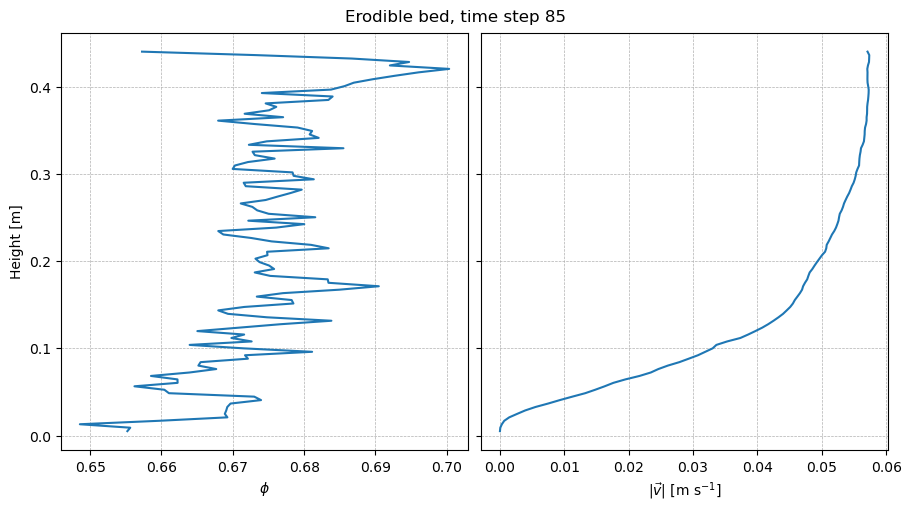

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(9, 5), sharey=True, constrained_layout=True)
phi = profiles_run["volume_fraction"].isel(time=0)
ax[0].plot(phi, phi["y"])
ax[0].set_xlabel(r"$\phi$")
ax[0].set_ylabel("Height [m]")
v = profiles_run["velocity"].isel(time=0)
ax[1].plot(np.sqrt((v**2).sum("dim1_3D")), v["y"])
ax[1].set_xlabel(r"$|\vec{v}|$ [m s$^{-1}$]")
for a in ax:
    a.grid(visible=True, linestyle="--", linewidth=0.5)
fig.suptitle(f"Erodible bed, time step {int(erosion_run.time[0])}")
plt.show()

### 2. Time series of vertical profiles

The following plots use the Pysammos output for 145 time steps (0.1 s apart) in `Pysammos_data_paper/`: the gridded fields and the sliced granular temperature.

In [14]:
manager = H5XarrayManager("../data_examples/erodible_bed/Pysammos_data_paper/CG_Lucy_Monodisperse.h5")
erosion_CG = manager.h5_to_xarray()

manager_gt = H5XarrayManager("../data_examples/erodible_bed/Pysammos_data_paper/CG_GranularTemperature_slices.h5")
slices_gt = manager_gt.h5_to_xarray()

Processing key: density_mixture
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: inertial_number_Sxy_Pxy_d32
Processing key: inertial_number_Sxy_Pxy_d43
Processing key: inertial_number_Sxy_Pxyz_d32
Processing key: inertial_number_Sxy_Pxyz_d43
Processing key: inertial_number_Sxy_Py_d32
Processing key: inertial_number_Sxy_Py_d43
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing key: pressure_xyz
Processing ke

The datasets hold the grid positions and the time steps as coordinates:

In [15]:
erosion_CG.positions

<xarray.DataArray 'positions' (point: 36075, xyz: 3)> Size: 866kB
array([[0.005  , 0.005  , 0.005  ],
       [0.005  , 0.005  , 0.00875],
       [0.005  , 0.005  , 0.0125 ],
       ...,
       [0.1    , 0.44   , 0.0425 ],
       [0.1    , 0.44   , 0.04625],
       [0.1    , 0.44   , 0.05   ]])
Coordinates:
  * point      (point) int64 289kB 0 1 2 3 4 5 ... 36070 36071 36072 36073 36074
    positions  (point, xyz) float64 866kB 0.005 0.005 0.005 ... 0.1 0.44 0.05
Dimensions without coordinates: xyz

In [16]:
erosion_CG.time

<xarray.DataArray 'time' (time: 145)> Size: 1kB
array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,  14,
        15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,  28,
        29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,  42,
        43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,  56,
        57,  58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,  70,
        71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,  84,
        85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,  98,
        99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112,
       113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126,
       127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140,
       141, 142, 143, 144, 145])
Coordinates:
  * time     (time) int64 1kB 1 2 3 4 5 6 7 8 ... 139 140 141 142 143 144 145

Vertical profiles of every time step:

In [17]:
VI = VerticalIntegrator(erosion_CG, "y")
vertical_ds_general = VI.integration()

Starting integration along profile dimension: y
Completed integration along profile dimension: y


The figure shows, from left to right:

- **(a)** the volume fraction profile of every time step, coloured by time;
- **(b)** the granular temperature in `x` averaged over the last second, from the slice methods (Zhang & Kamrin, 2017, and the LAMMPS definition) and from the gridded fields;
- **(c)** the gridded granular temperature of every time step, with the averages over the first and last second;
- **(d)** the velocity magnitude of every time step, with the averages over the first and last second.

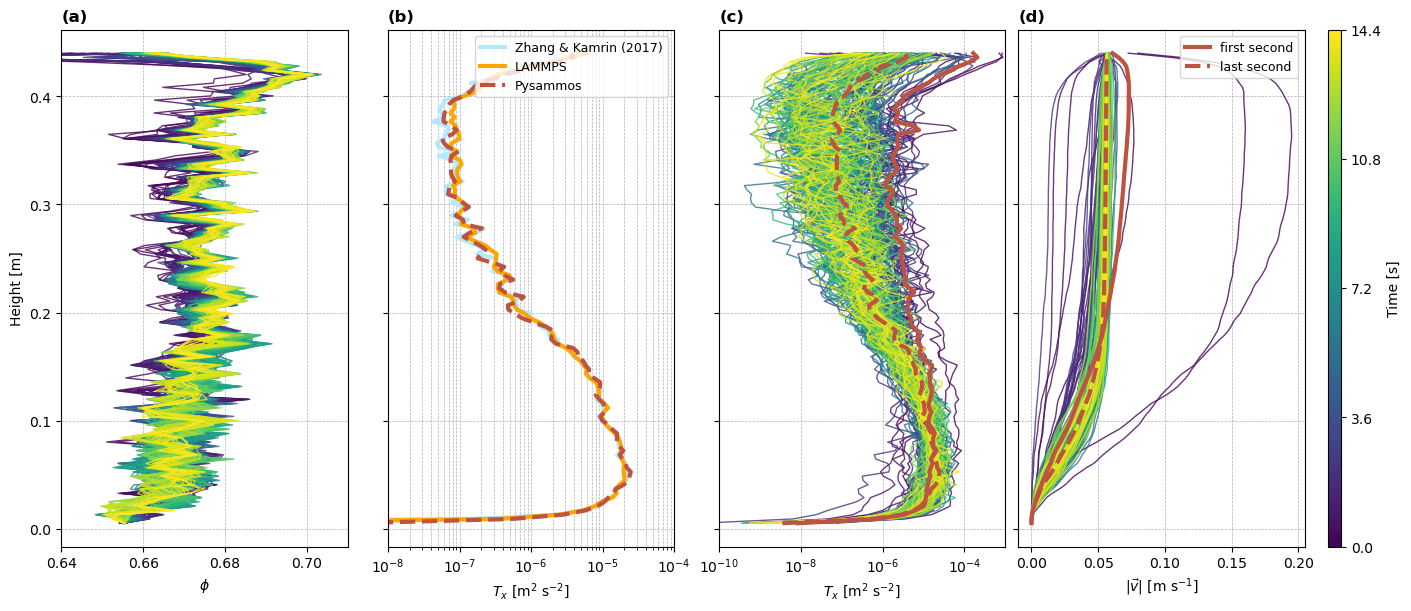

In [18]:
dt = 0.1                                  # time between output steps [s]
n_steps = erosion_CG.sizes["time"]
n_window = int(round(1.0 / dt))           # number of steps in one second
first, last = slice(0, n_window), slice(-n_window, None)

cmap = plt.cm.viridis
norm = mpl.colors.Normalize(vmin=0, vmax=n_steps - 1)

phi = vertical_ds_general["volume_fraction"]
T_x = vertical_ds_general["granular_temperature_x"]
vel = vertical_ds_general["velocity"]
vel_mag = np.sqrt((vel**2).sum("dim1_3D"))
y = vertical_ds_general["y"].values

fig, ax = plt.subplots(1, 4, figsize=(14, 6), sharey=True, constrained_layout=True)

# (a) volume fraction
for i in range(n_steps):
    ax[0].plot(phi.isel(time=i), y, color=cmap(norm(i)), alpha=0.8, lw=1)

# (b) granular temperature: slices vs gridded, last second
y_slices = slices_gt.positions[:, 1]
ax[1].plot(slices_gt.granular_temperature_Kamrin[-n_window:, :, 0].mean(axis=0), y_slices,
           color="#B3E9FF", lw=3, label="Zhang & Kamrin (2017)")
ax[1].plot(slices_gt.granular_temperature_LAMMPS[-n_window:, :, 0].mean(axis=0), y_slices,
           color="orange", lw=3, label="LAMMPS")
ax[1].plot(T_x.isel(time=last).mean("time"), y, color="#BD5340", ls="--", lw=3, label="Pysammos")

# (c) gridded granular temperature, every step + first/last second
for i in range(n_steps):
    ax[2].plot(T_x.isel(time=i), y, color=cmap(norm(i)), alpha=0.8, lw=1)
ax[2].plot(T_x.isel(time=first).mean("time"), y, color="#BD5340", lw=3, label="first second")
ax[2].plot(T_x.isel(time=last).mean("time"), y, color="#BD5340", ls="--", lw=3, label="last second")

# (d) velocity magnitude, every step + first/last second
for i in range(n_steps):
    ax[3].plot(vel_mag.isel(time=i), y, color=cmap(norm(i)), alpha=0.8, lw=1)
ax[3].plot(vel_mag.isel(time=first).mean("time"), y, color="#BD5340", lw=3, label="first second")
ax[3].plot(vel_mag.isel(time=last).mean("time"), y, color="#BD5340", ls="--", lw=3, label="last second")

# colour bar: time
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax[3], aspect=40)
ticks = np.linspace(0, n_steps - 1, 5)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t * dt:.1f}" for t in ticks])
cbar.set_label("Time [s]")

# labels
ax[0].set_ylabel("Height [m]")
ax[0].set_xlabel(r"$\phi$")
ax[1].set_xlabel(r"$T_x$ [m$^2$ s$^{-2}$]")
ax[2].set_xlabel(r"$T_x$ [m$^2$ s$^{-2}$]")
ax[3].set_xlabel(r"$|\vec{v}|$ [m s$^{-1}$]")
ax[0].set_xlim(0.64, 0.71)
ax[1].set_xscale("log"); ax[1].set_xlim(1e-8, 1e-4)
ax[2].set_xscale("log"); ax[2].set_xlim(1e-10, 1e-3)
ax[1].legend(fontsize=9, loc="upper right")
ax[3].legend(fontsize=9, loc="upper right")
for a, label in zip(ax, ["(a)", "(b)", "(c)", "(d)"]):
    a.grid(visible=True, which="both", linestyle="--", linewidth=0.5)
    a.set_title(label, loc="left", fontweight="bold")
plt.show()

The gridded granular temperature is lower than the slice temperatures: it is computed relative to the coarse-grained velocity field at the kernel scale `w`, so it depends on `w` (see the documentation of the sliced granular temperature).